In [2]:
import requests
import pandas as pd
import time
from requests.adapters import HTTPAdapter
from urllib3.util.retry import Retry



START_DATE = "1980-01-01"
END_DATE = "2020-12-31"

OUTPUT_CSV = "sondrio_weather_1980_2020.csv"

# pausa standard tra richieste: altrimenti lo script fallisce per too many requests (err 429)
REQUEST_DELAY = 5


DB_CONFIG = {
    "host": "aws-0-eu-west-1.pooler.supabase.com",
    "port": 6543,
    "database": "postgres",
    "user": "postgres.palaoxigjbvbrgdnbstd",
    "password": "@ghZ2XjxsdL_*m*"
}

url = URL.create(
    drivername="postgresql+psycopg2",
    username=DB_CONFIG["user"],
    password=DB_CONFIG["password"],
    host=DB_CONFIG["host"],
    port=DB_CONFIG["port"],
    database=DB_CONFIG["database"]
)

engine = create_engine(url)





#comuni

comuni = [
    ("Sondrio", 46.169, 9.871),
    ("Tirano", 46.216, 10.169),
    ("Bormio", 46.468, 10.373),
    ("Livigno", 46.538, 10.135),
    ("Morbegno", 46.133, 9.574),
    ("Chiavenna", 46.321, 9.399),
    ("Aprica", 46.154, 10.151),
    ("Valdisotto", 46.429, 10.357),
    ("Valfurva", 46.420, 10.490),
    ("Piantedo", 46.133, 9.430),
]

#metto il retry

session = requests.Session()

retry_strategy = Retry(
    total=5,
    backoff_factor=10,
    status_forcelist=[429, 500, 502, 503, 504],
    allowed_methods=["GET"]
)

adapter = HTTPAdapter(max_retries=retry_strategy)

session.mount("https://", adapter)
session.mount("http://", adapter)

################################
##snowfall è in cm, rainfall è in mm e temp in celsius
def scarica_dati(nome, lat, lon):

    url = (
        "https://archive-api.open-meteo.com/v1/archive"
        f"?latitude={lat}"
        f"&longitude={lon}"
        f"&start_date={START_DATE}"
        f"&end_date={END_DATE}"
        "&daily=temperature_2m_mean,rain_sum,snowfall_sum"
        "&timezone=Europe/Rome"
    )

    tentativi = 0
    max_tentativi = 5

    while tentativi < max_tentativi:

        try:

            print(f"Scarico dati per {nome}...")

            response = session.get(url, timeout=120)

            # RATE LIMIT: 429 è l'err di too many requests
            if response.status_code == 429:

                wait_time = 30 * (tentativi + 1)

                print(f"429 per {nome} -> attendo {wait_time}s")

                time.sleep(wait_time)

                tentativi += 1
                continue

            response.raise_for_status()

            data = response.json()

            if "daily" not in data:
                print(f"Nessun dato per {nome}")
                return None

            df = pd.DataFrame({
                "date": data["daily"]["time"],
                "temperature_mean": data["daily"]["temperature_2m_mean"],
                "rain_sum": data["daily"]["rain_sum"],
                "snowfall_sum": data["daily"]["snowfall_sum"]
            })

            df["date"] = pd.to_datetime(df["date"])

            df["year"] = df["date"].dt.year
            df["month"] = df["date"].dt.month

            monthly = (
                df.groupby(["year", "month"])
                .agg({
                    "temperature_mean": "mean",
                    "rain_sum": "sum",
                    "snowfall_sum": "sum"
                })
                .reset_index()
            )

            monthly["comune"] = nome

            return monthly

        except Exception as e:

            tentativi += 1

            print(f"Errore {nome}: {e}")

            wait_time = 15 * tentativi

            print(f"Retry tra {wait_time}s")

            time.sleep(wait_time)

    print(f"Fallito definitivamente: {nome}")

    return None

#loop principle

all_data = []

for nome, lat, lon in comuni:

    df = scarica_dati(nome, lat, lon)

    if df is not None:

        all_data.append(df)

        # salvataggio progressivo
        temp_df = pd.concat(all_data, ignore_index=True)

        temp_df.to_csv(OUTPUT_CSV, index=False)

        print(f"Salvataggio parziale: {OUTPUT_CSV}")

    # pausa tra comuni
    time.sleep(REQUEST_DELAY)

#export del csv

if all_data:

    final_df = pd.concat(all_data, ignore_index=True)

    final_df = final_df[
        [
            "comune",
            "year",
            "month",
            "temperature_mean",
            "rain_sum",
            "snowfall_sum"
        ]
    ]

    final_df.to_csv(OUTPUT_CSV, index=False)

    print(f"\nCSV finale salvato: {OUTPUT_CSV}")

else:
    print("Nessun dato scaricato.")

Scarico dati per Sondrio...
Salvataggio parziale: sondrio_weather_1980_2020.csv
Scarico dati per Tirano...
Salvataggio parziale: sondrio_weather_1980_2020.csv
Scarico dati per Bormio...
Salvataggio parziale: sondrio_weather_1980_2020.csv
Scarico dati per Livigno...
Salvataggio parziale: sondrio_weather_1980_2020.csv
Scarico dati per Morbegno...
Salvataggio parziale: sondrio_weather_1980_2020.csv
Scarico dati per Chiavenna...
Salvataggio parziale: sondrio_weather_1980_2020.csv
Scarico dati per Aprica...
Salvataggio parziale: sondrio_weather_1980_2020.csv
Scarico dati per Valdisotto...
Salvataggio parziale: sondrio_weather_1980_2020.csv
Scarico dati per Valfurva...
Salvataggio parziale: sondrio_weather_1980_2020.csv
Scarico dati per Piantedo...
Salvataggio parziale: sondrio_weather_1980_2020.csv

CSV finale salvato: sondrio_weather_1980_2020.csv


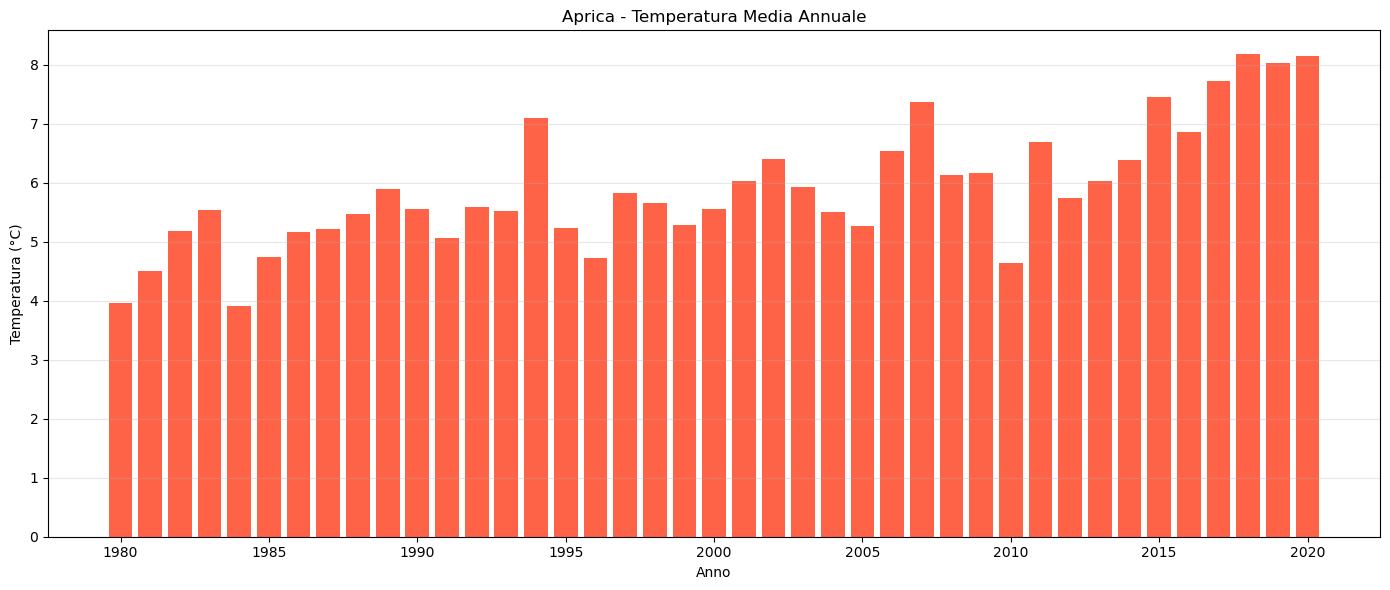

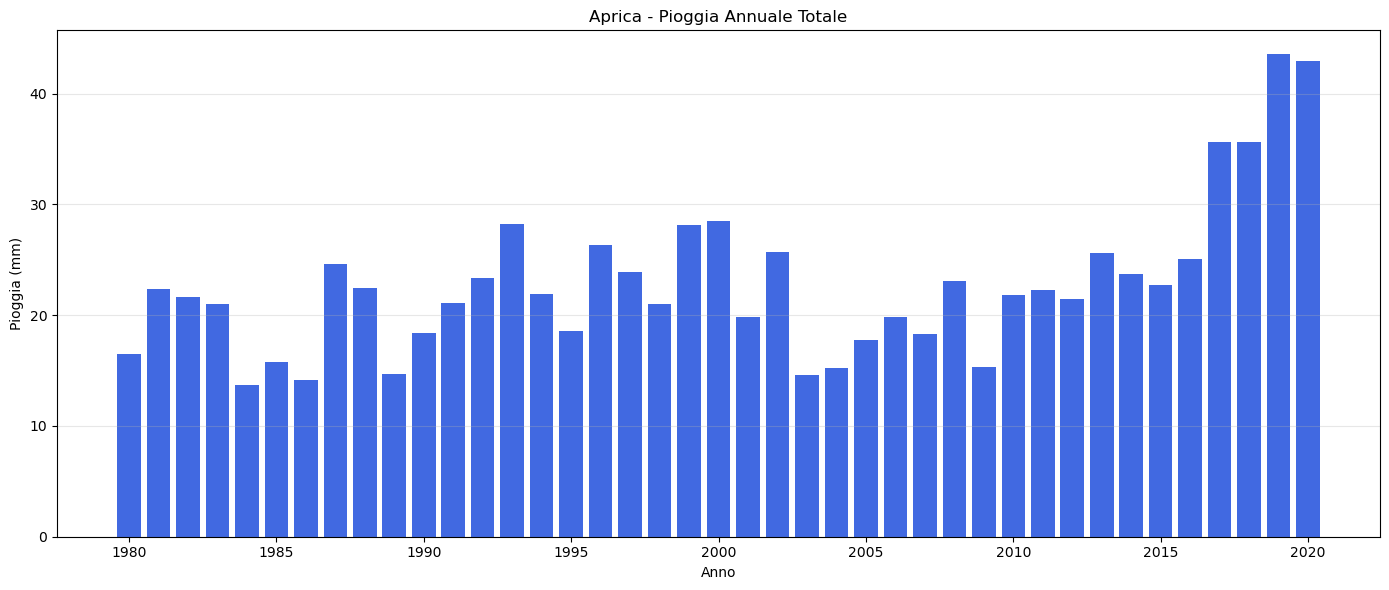

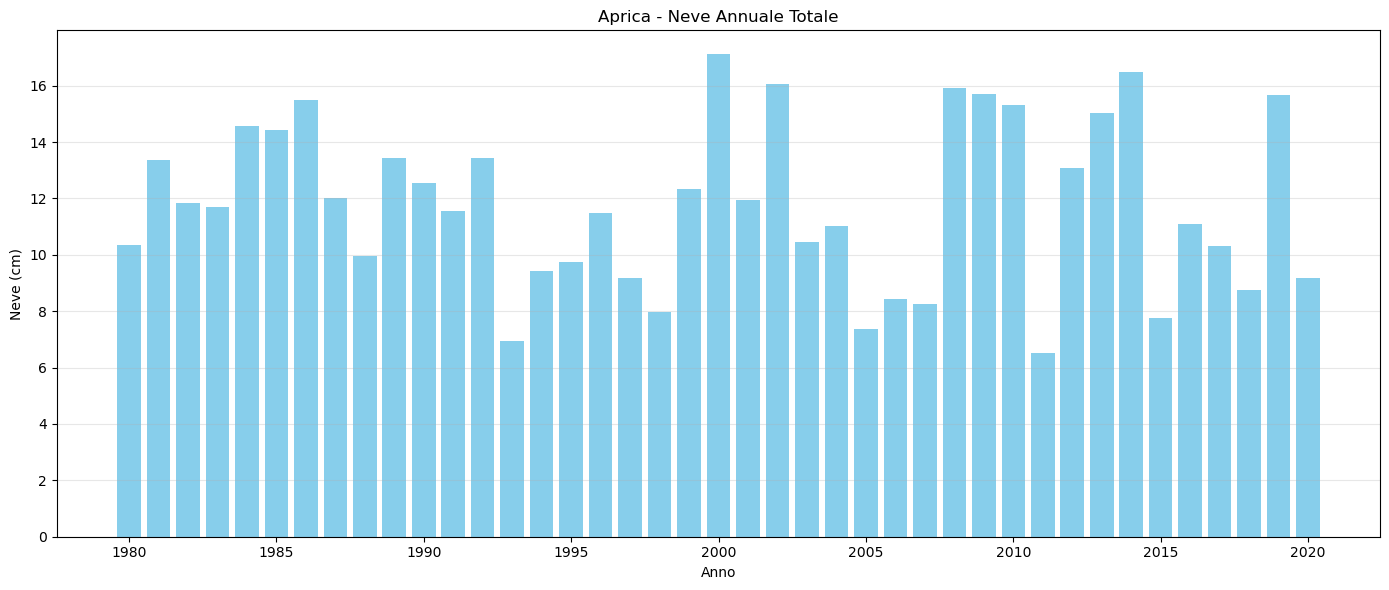

Grafici creati per Aprica


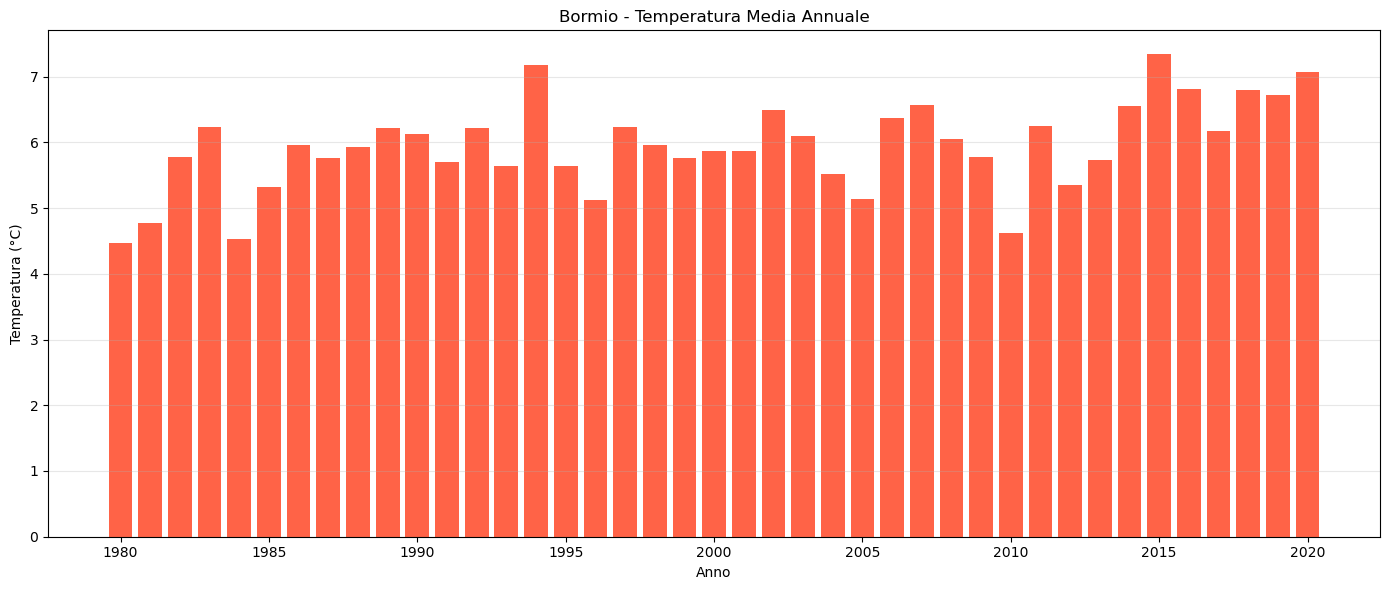

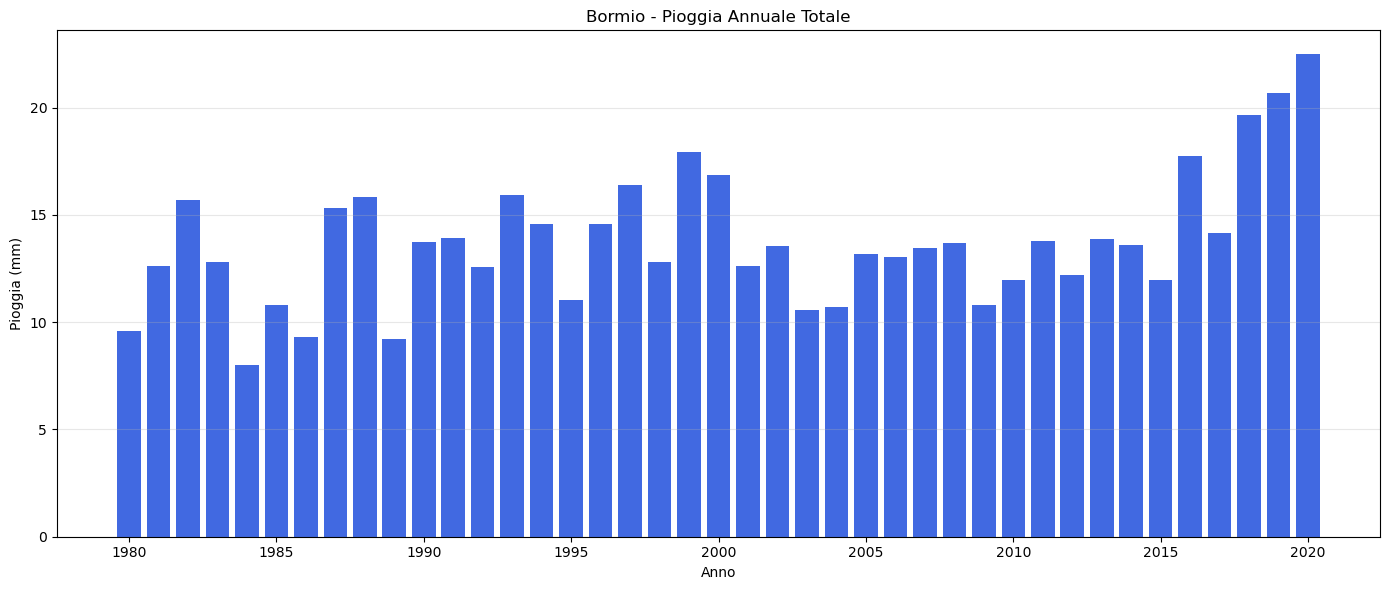

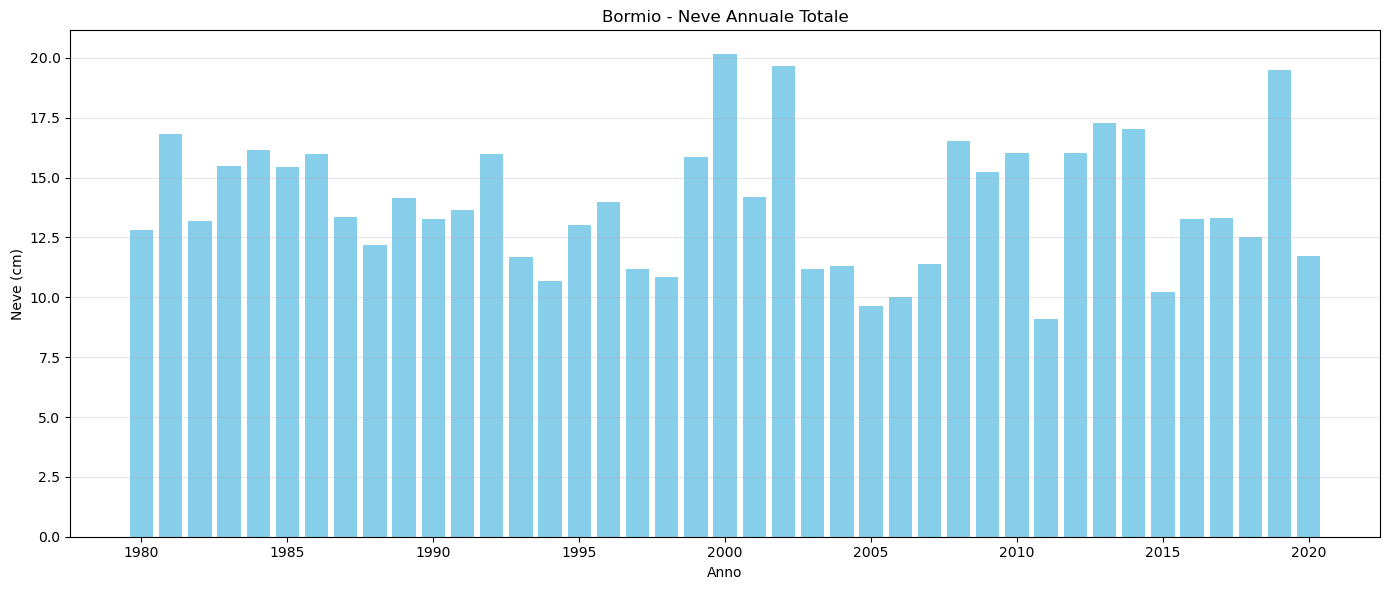

Grafici creati per Bormio


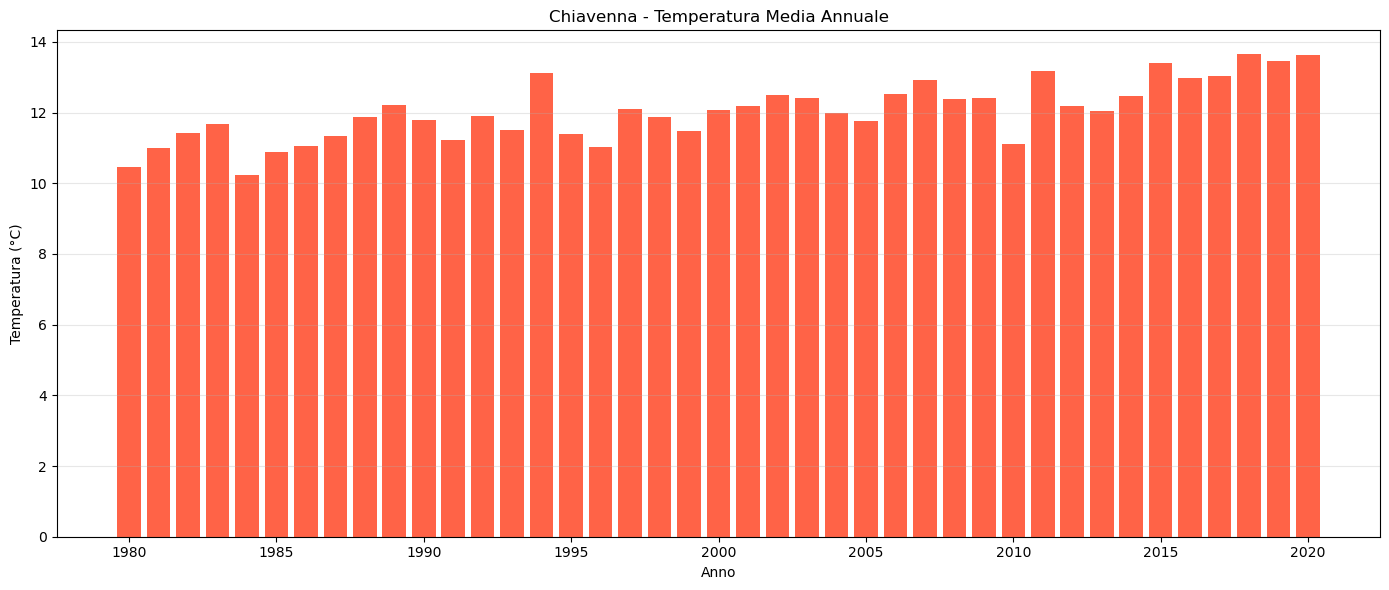

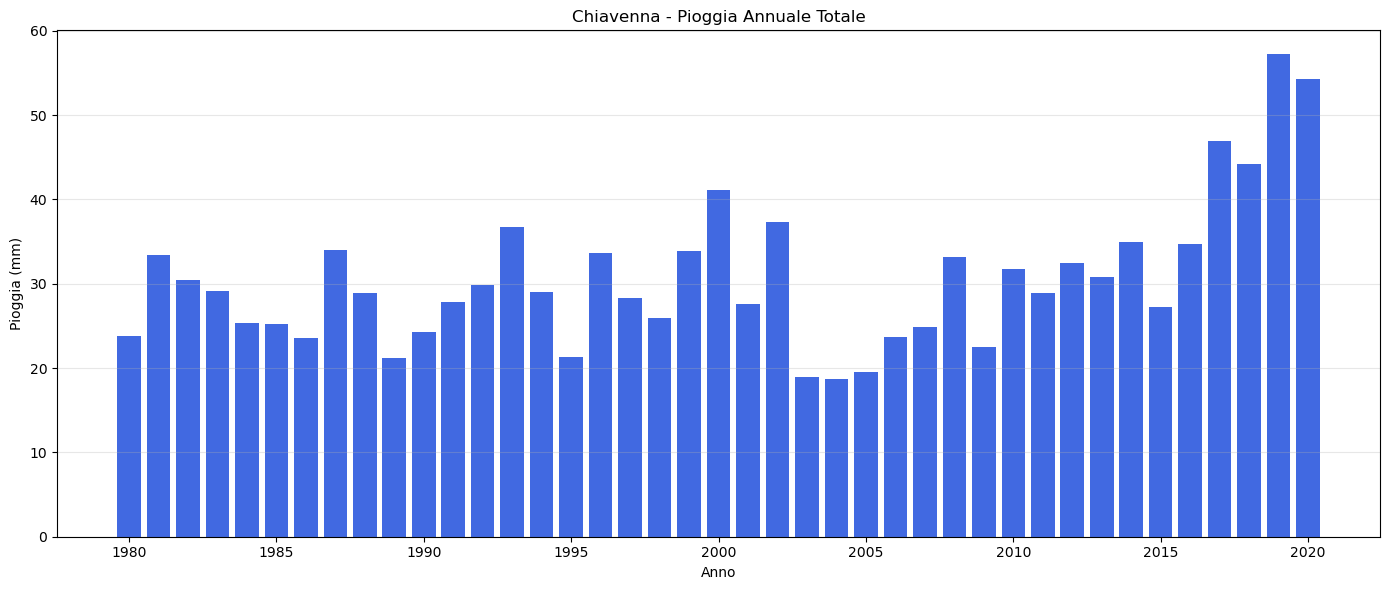

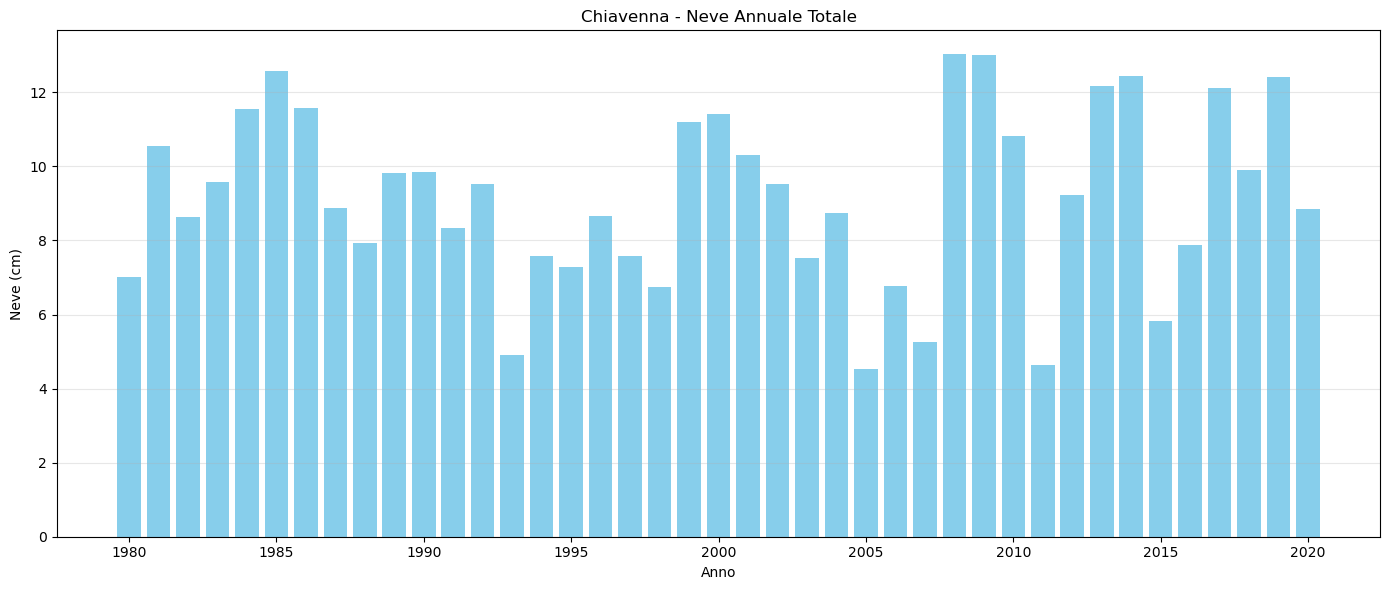

Grafici creati per Chiavenna


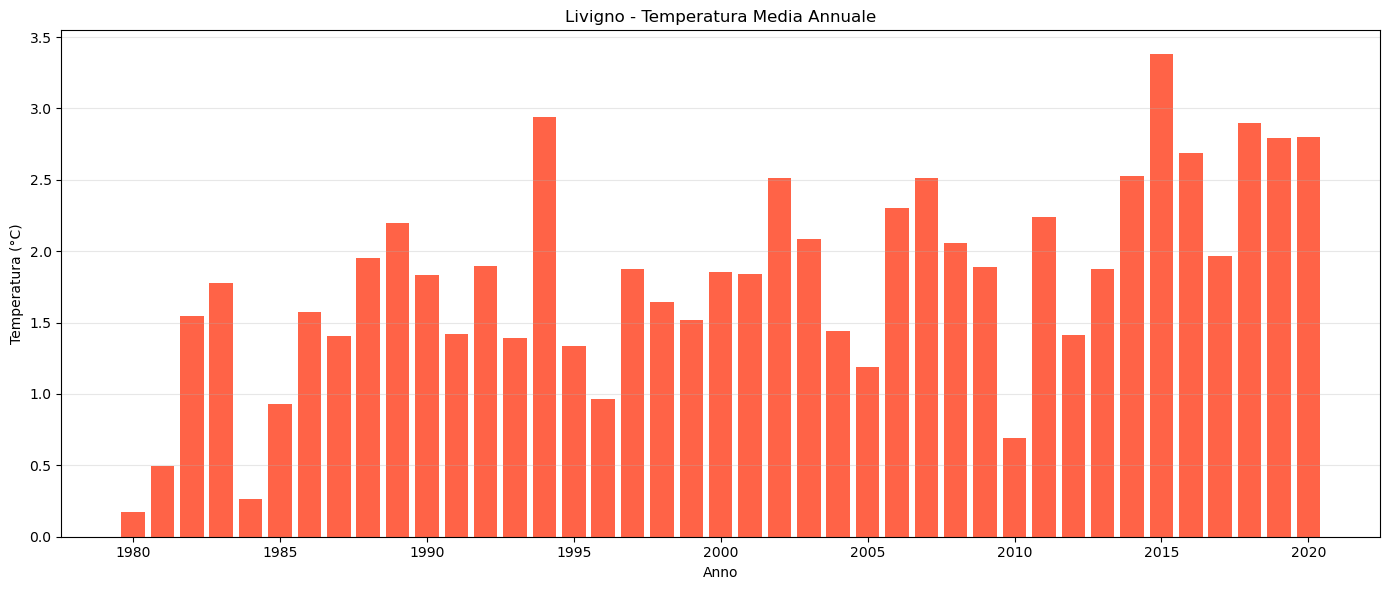

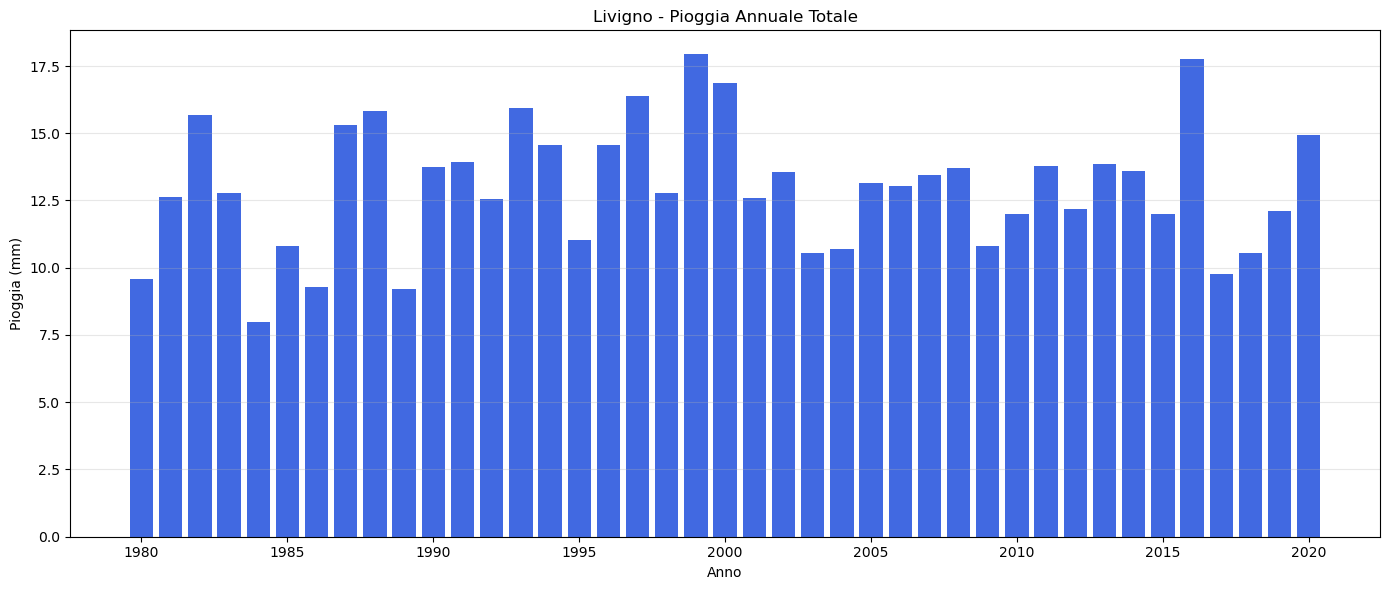

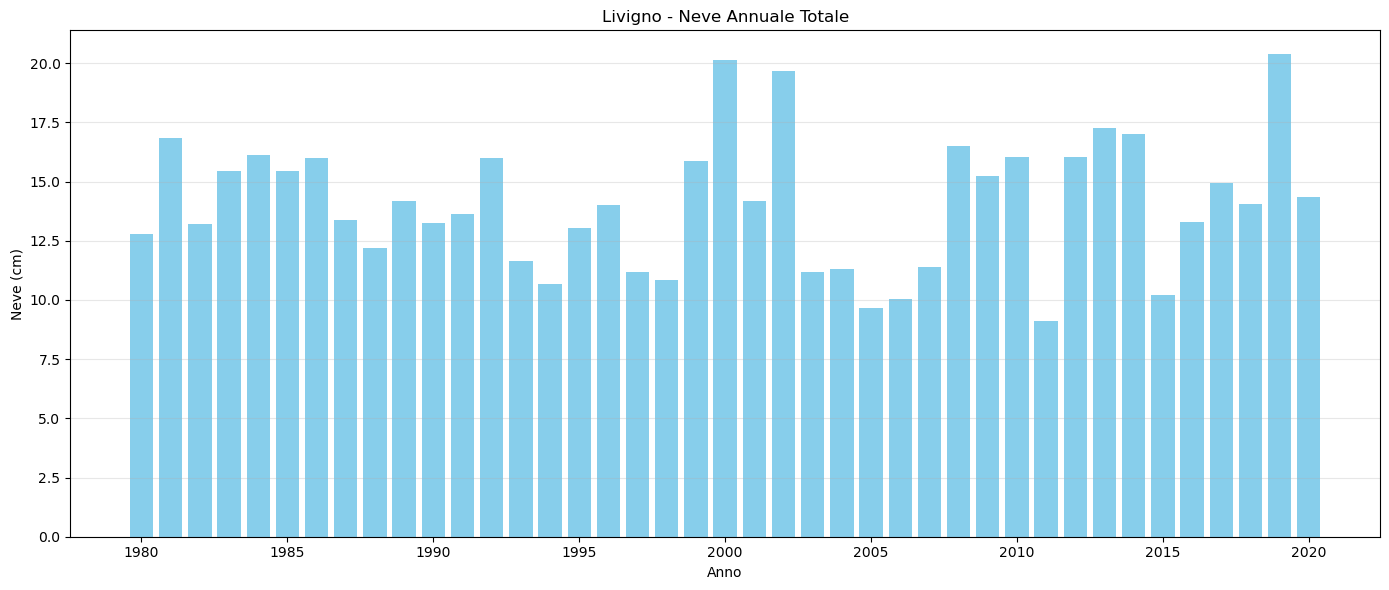

Grafici creati per Livigno


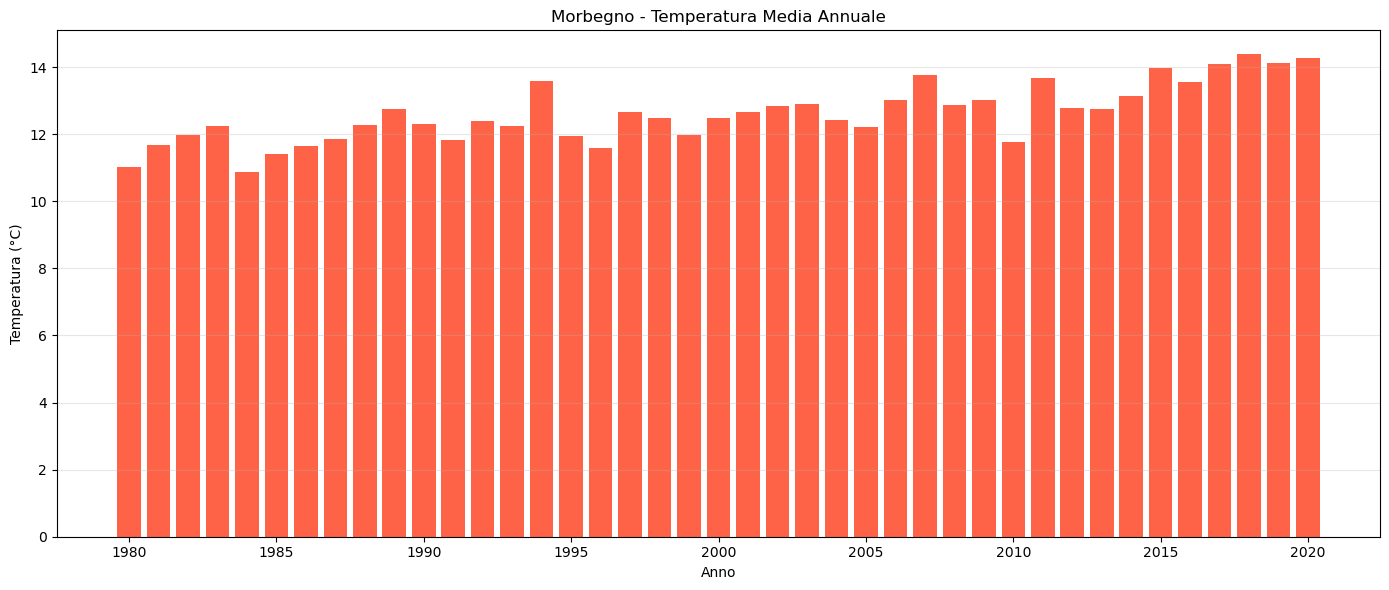

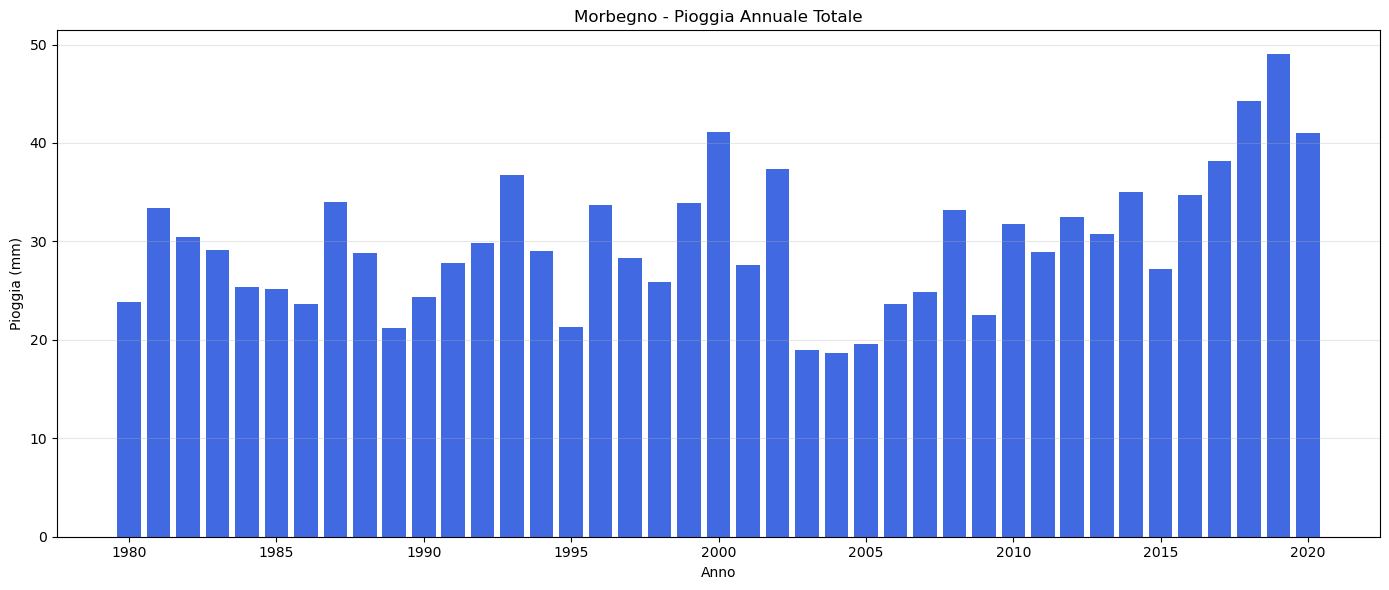

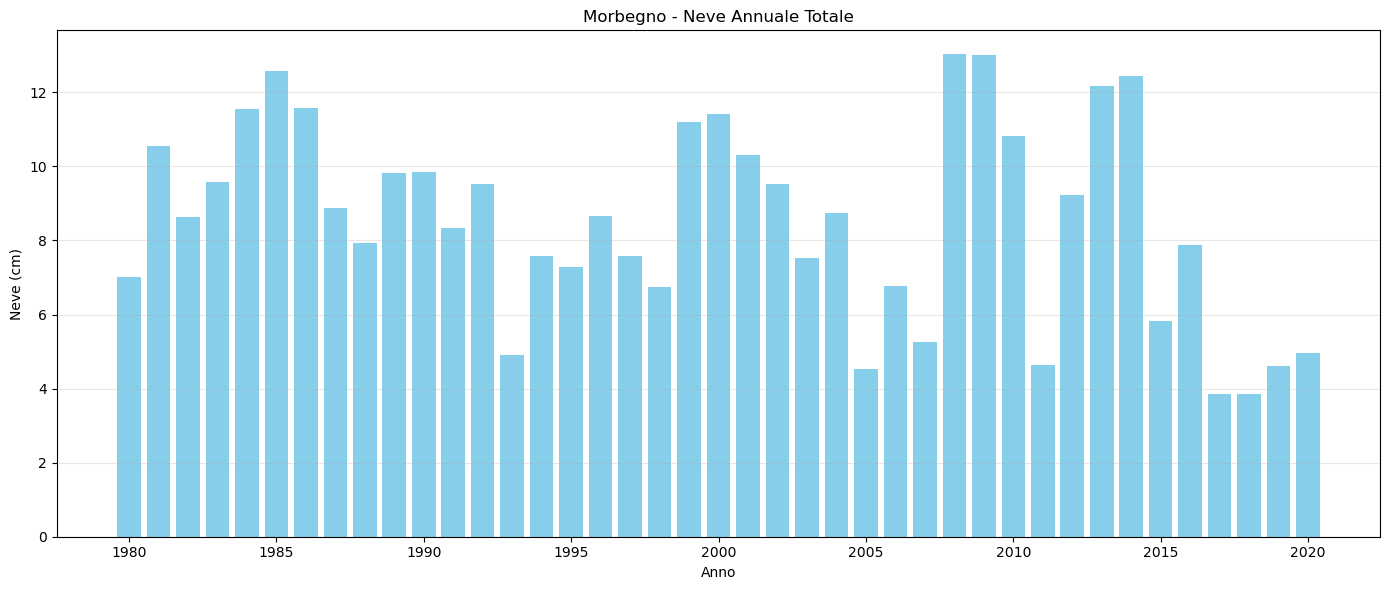

Grafici creati per Morbegno


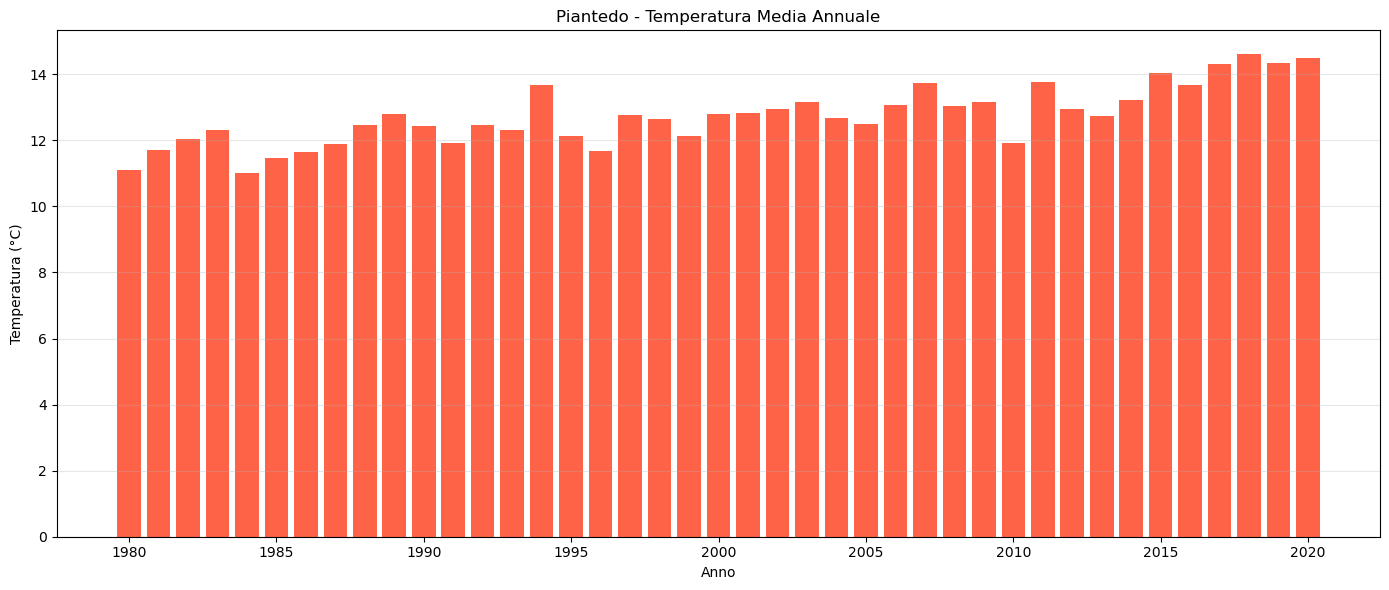

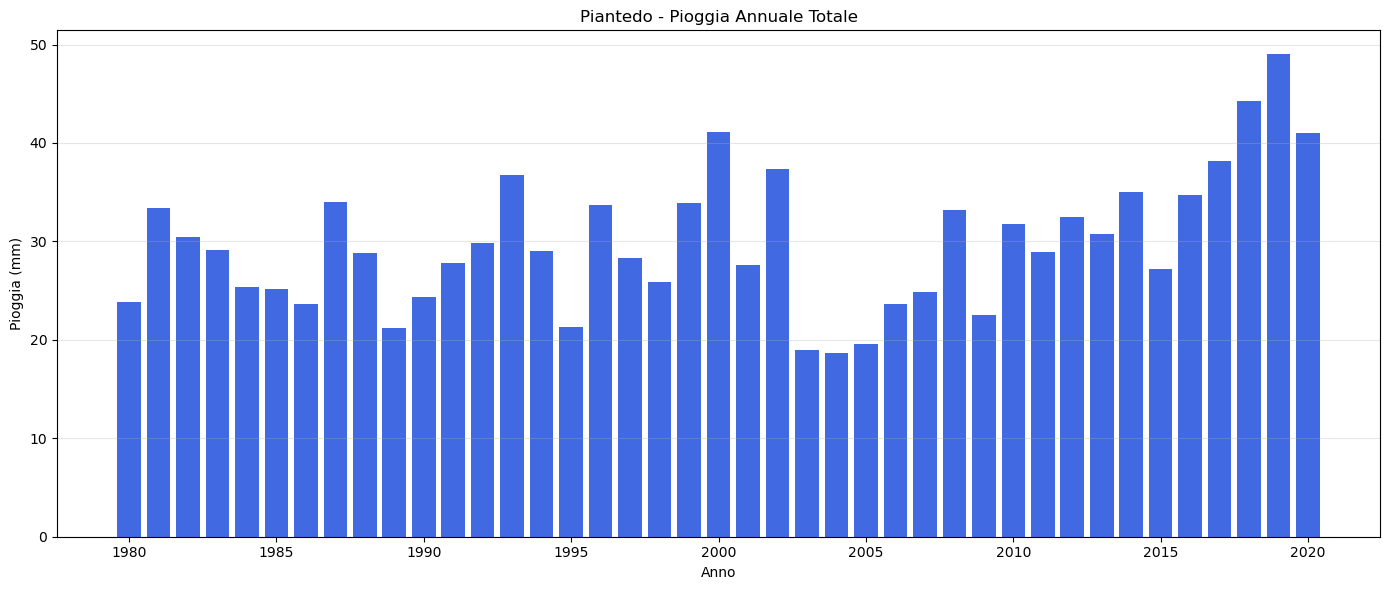

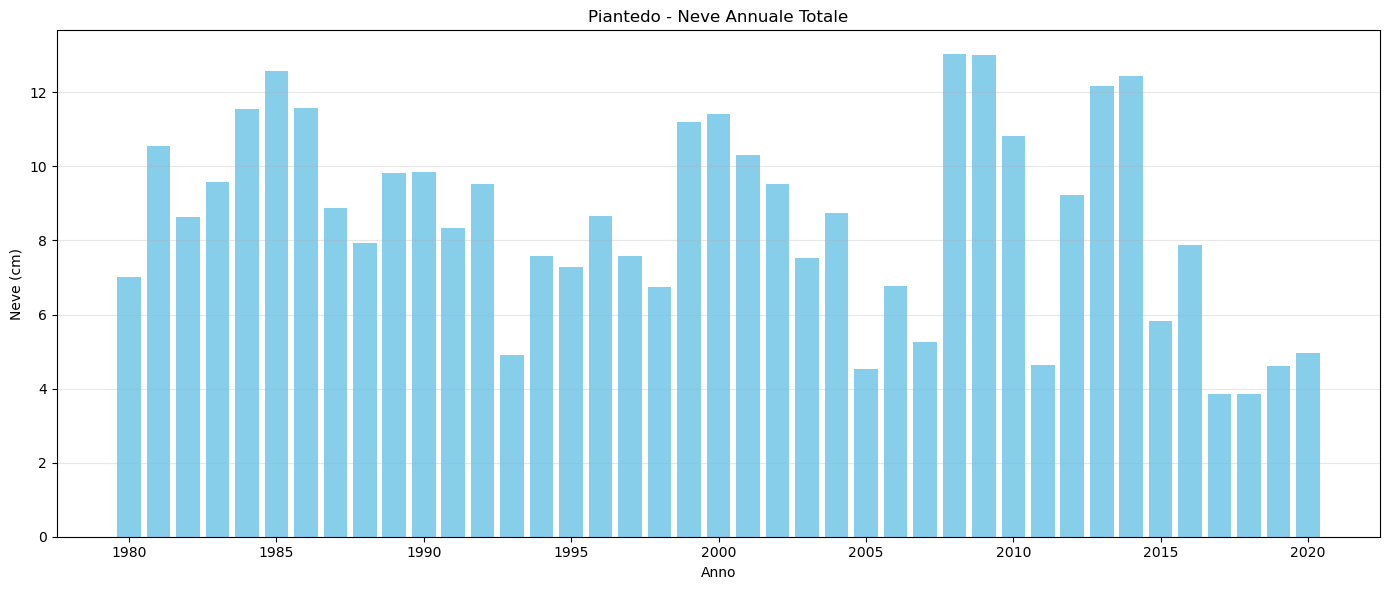

Grafici creati per Piantedo


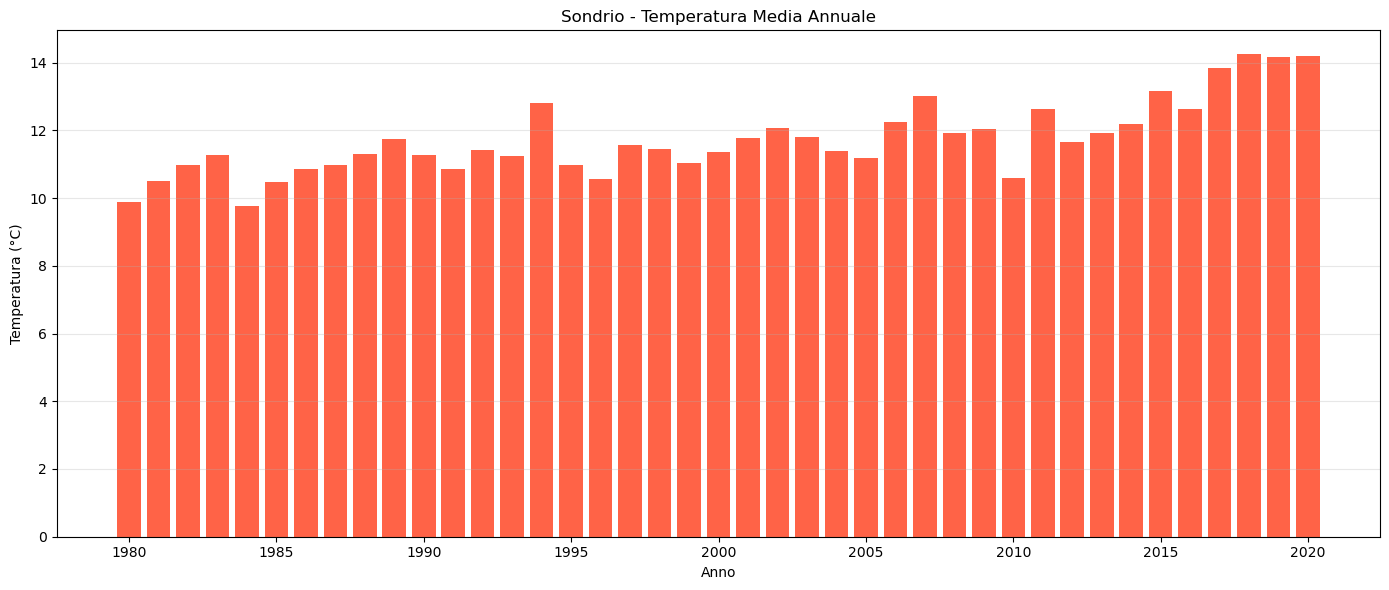

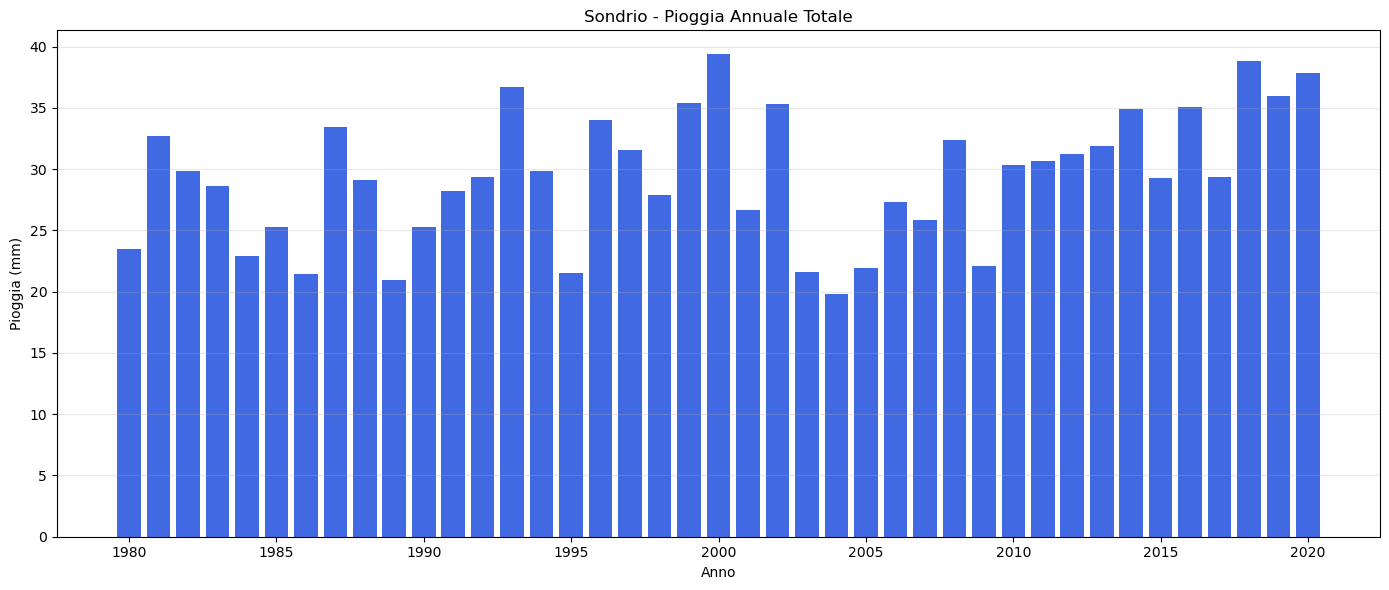

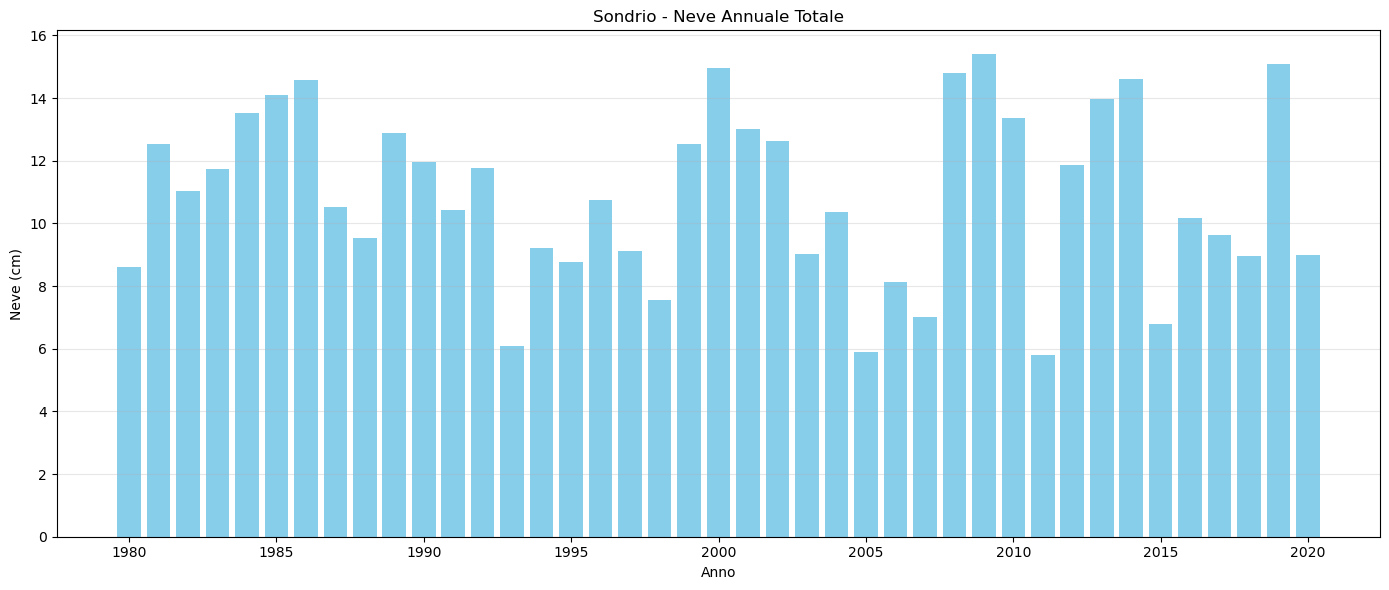

Grafici creati per Sondrio


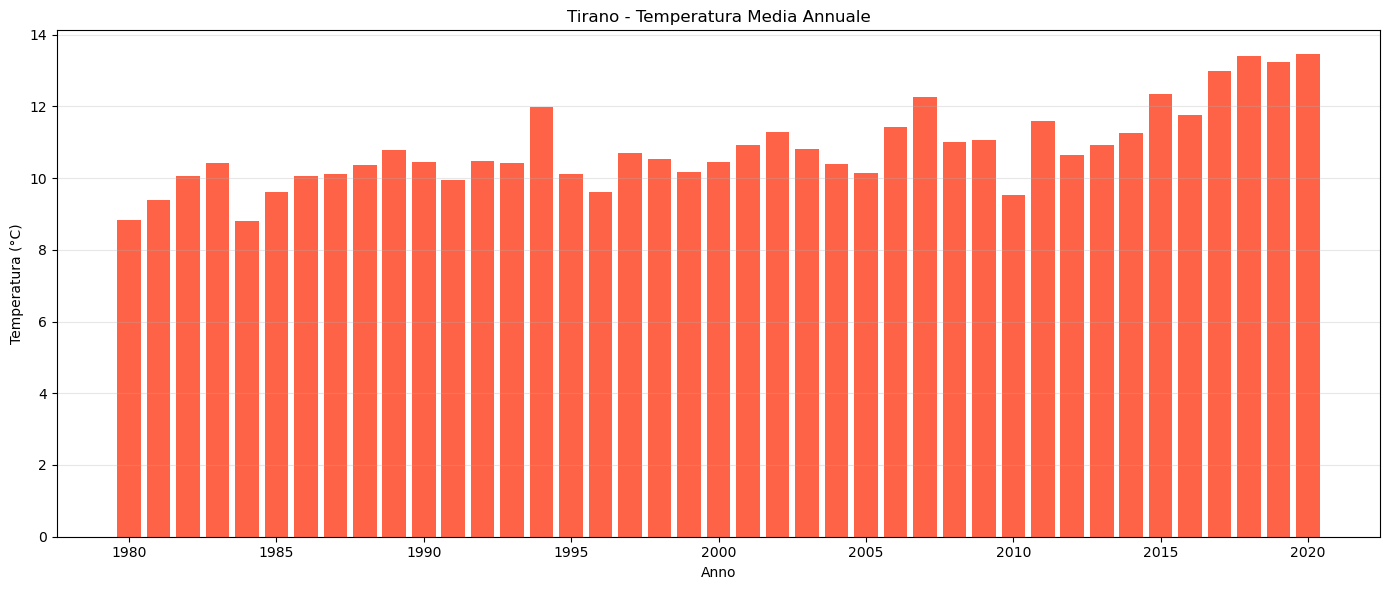

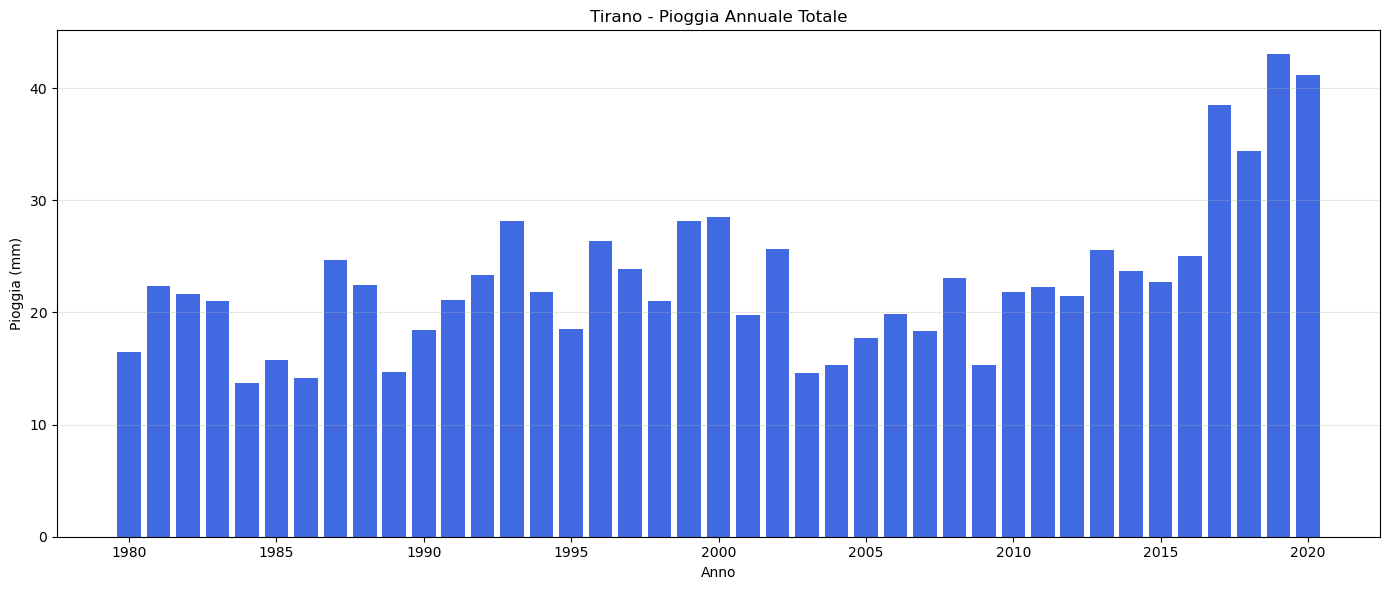

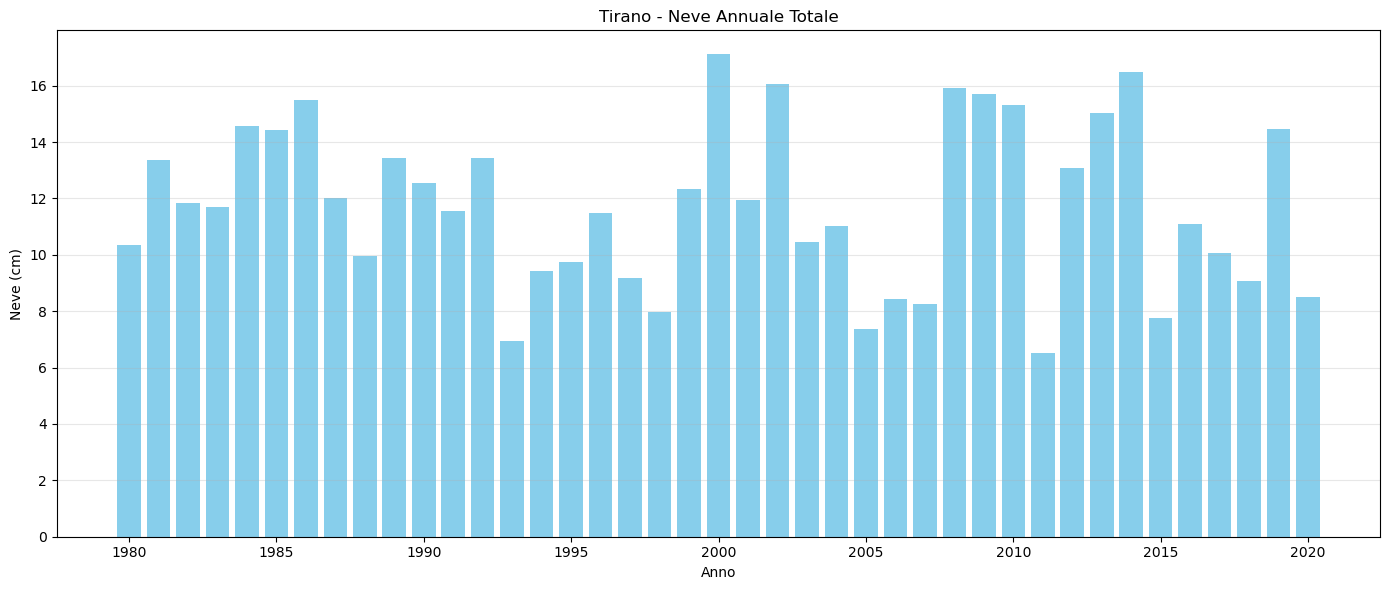

Grafici creati per Tirano


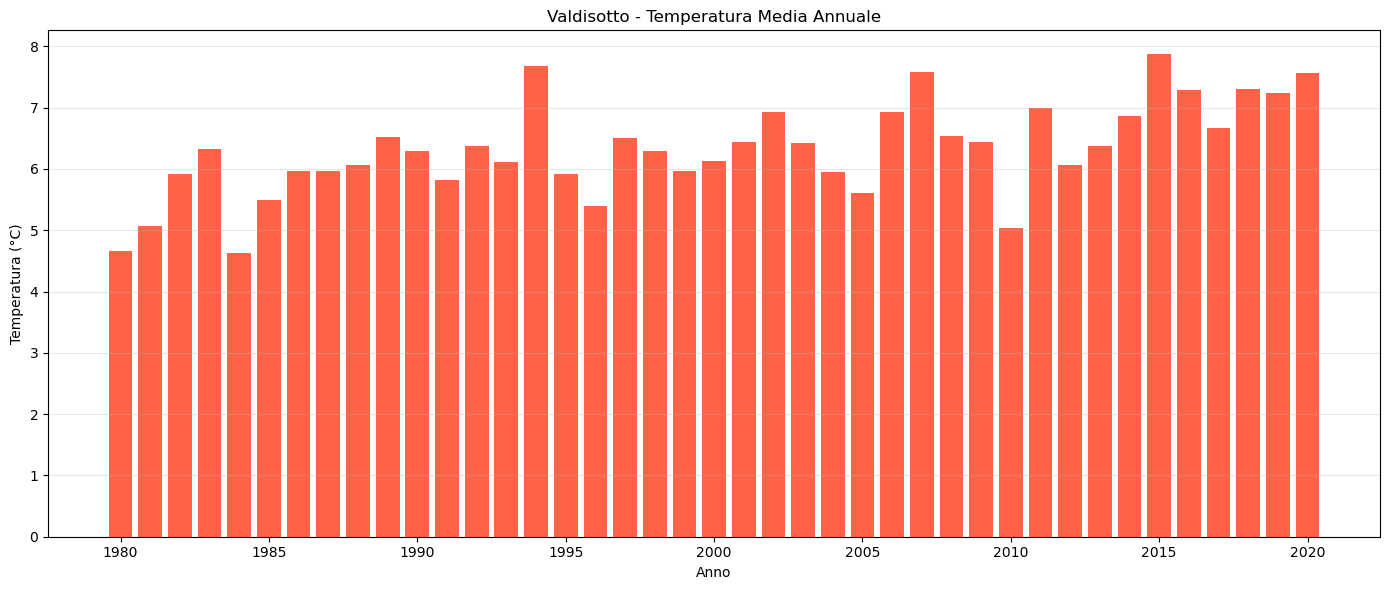

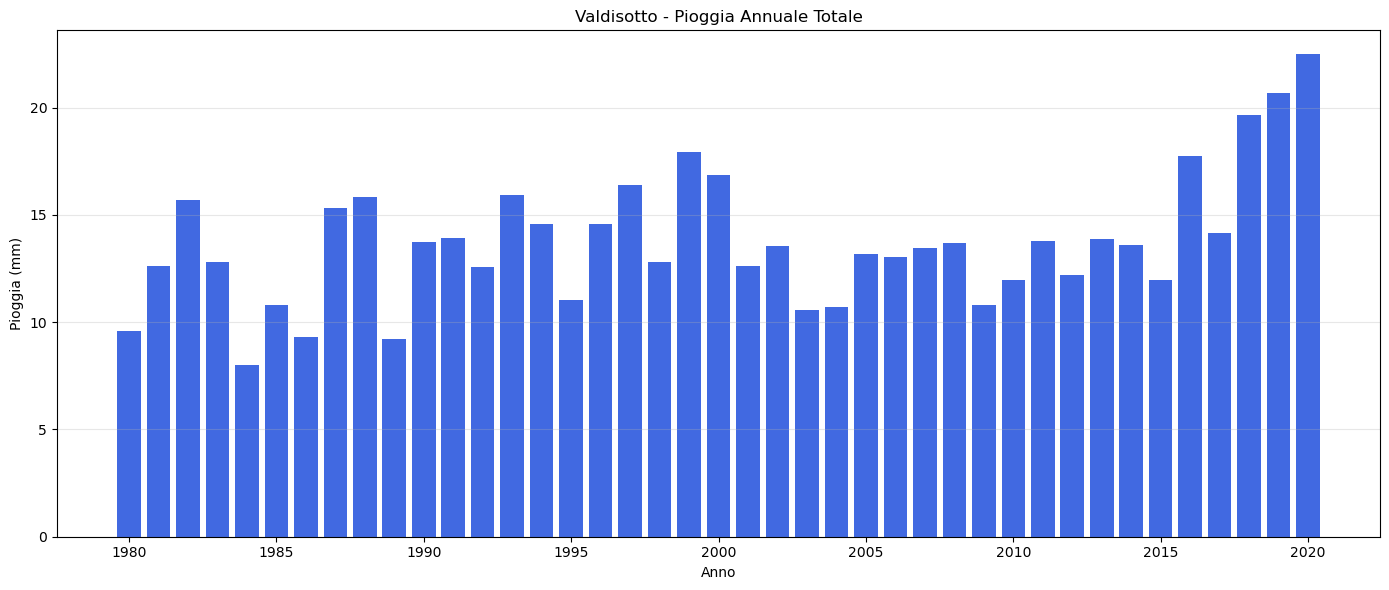

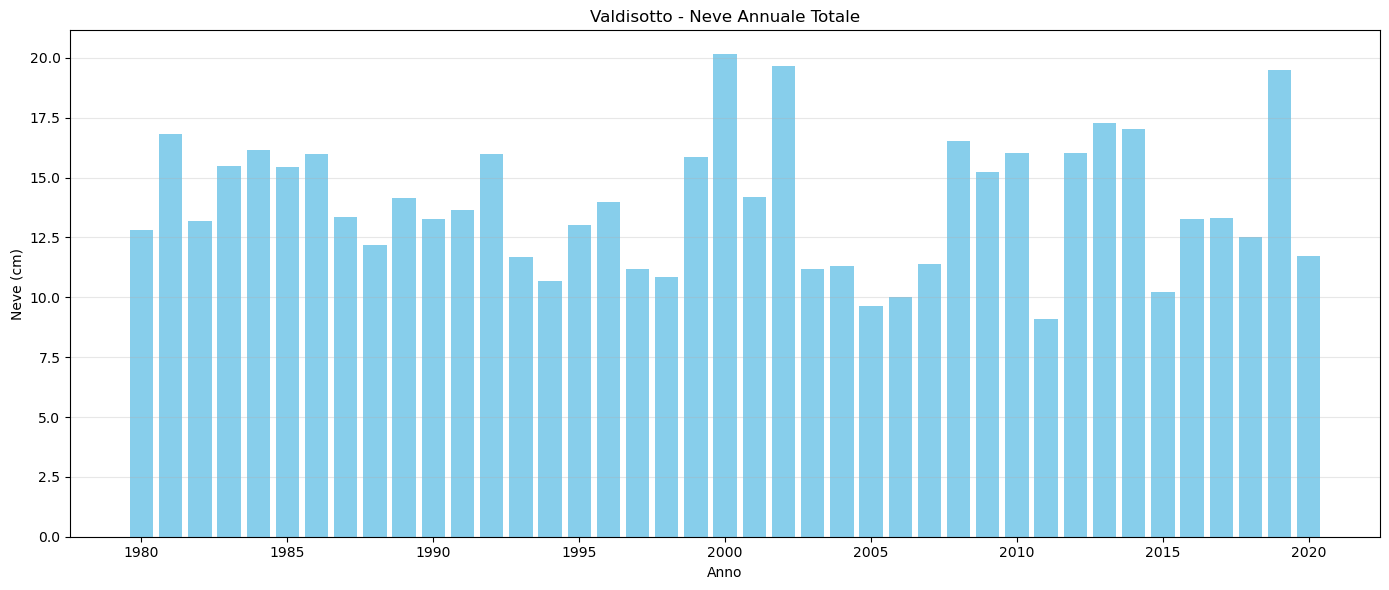

Grafici creati per Valdisotto


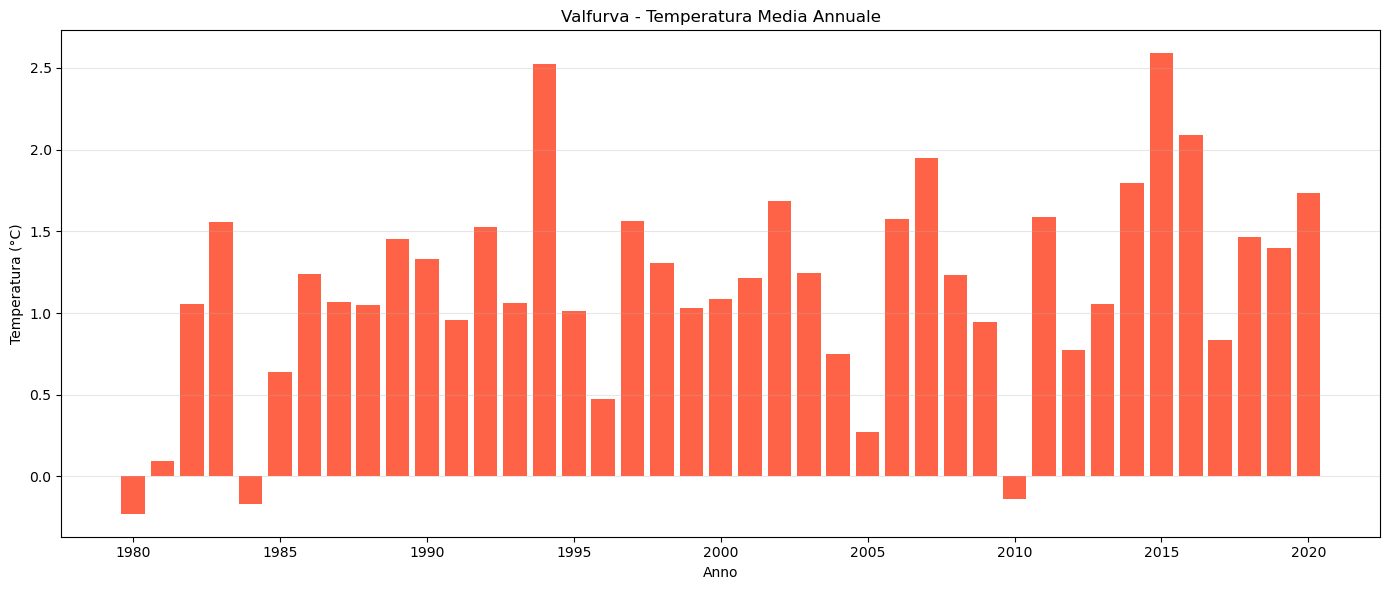

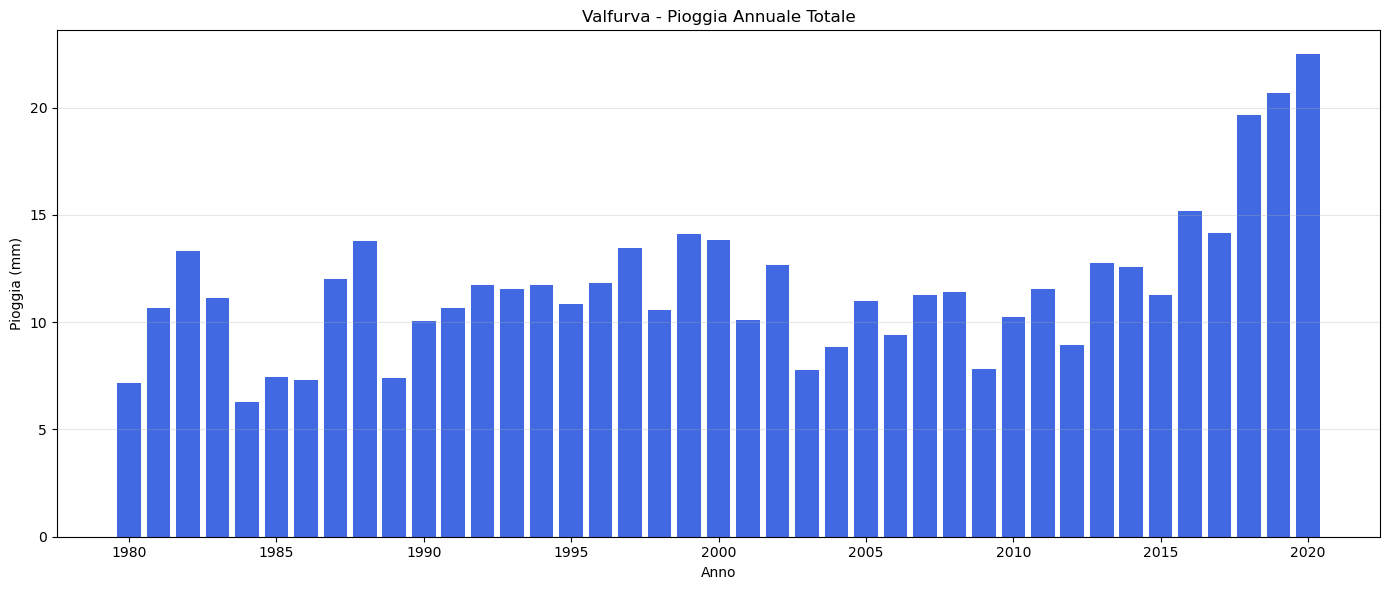

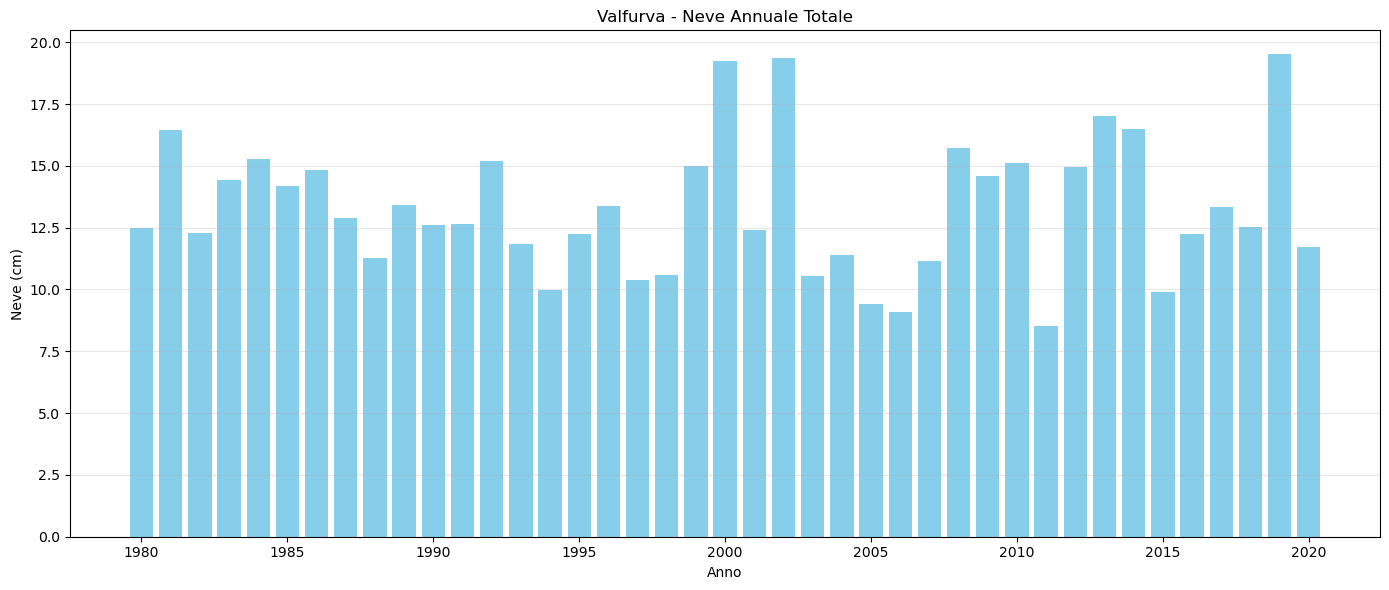

Grafici creati per Valfurva


In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import os


CSV_FILE = "sondrio_weather_1980_2020.csv"

# cartelle output
TEMP_DIR = "grafici_temperatura"
RAIN_DIR = "grafici_pioggia"
SNOW_DIR = "grafici_neve"

os.makedirs(TEMP_DIR, exist_ok=True)
os.makedirs(RAIN_DIR, exist_ok=True)
os.makedirs(SNOW_DIR, exist_ok=True)



df = pd.read_csv(CSV_FILE)

#raggruppo per anno: temperatura-->media, neve e pioggia---> somma

annual = (
    df.groupby(["comune", "year"])
    .agg({
        "temperature_mean": "mean",
        "rain_sum": "sum",
        "snowfall_sum": "sum"
    })
    .reset_index()
)

#comuni presenti nel csv

comuni = annual["comune"].unique()

#creo i grafici

for comune in comuni:

    subset = annual[annual["comune"] == comune]

    years = subset["year"]


    # temp


    plt.figure(figsize=(14, 6))

    plt.bar(
        years,
        subset["temperature_mean"],
        color="tomato"
    )

    plt.title(f"{comune} - Temperatura Media Annuale")
    plt.xlabel("Anno")
    plt.ylabel("Temperatura (°C)")

    plt.grid(axis='y', alpha=0.3)

    plt.tight_layout()

    temp_path = f"{TEMP_DIR}/{comune}_temperatura.png"

    plt.savefig(temp_path, dpi=150)

    plt.show()

    plt.close()


    # pioggia

    plt.figure(figsize=(14, 6))

    plt.bar(
        years,
        subset["rain_sum"],
        color="royalblue"
    )

    plt.title(f"{comune} - Pioggia Annuale Totale")
    plt.xlabel("Anno")
    plt.ylabel("Pioggia (mm)")

    plt.grid(axis='y', alpha=0.3)

    plt.tight_layout()

    rain_path = f"{RAIN_DIR}/{comune}_pioggia.png"

    plt.savefig(rain_path, dpi=150)

    plt.show()

    plt.close()


    # neve

    plt.figure(figsize=(14, 6))

    plt.bar(
        years,
        subset["snowfall_sum"],
        color="skyblue"
    )

    plt.title(f"{comune} - Neve Annuale Totale")
    plt.xlabel("Anno")
    plt.ylabel("Neve (cm)")

    plt.grid(axis='y', alpha=0.3)

    plt.tight_layout()

    snow_path = f"{SNOW_DIR}/{comune}_neve.png"

    plt.savefig(snow_path, dpi=150)

    plt.show()

    plt.close()

    print(f"Grafici creati per {comune}")